## Compare performance with traditional ML models by manually implementing evaluation metrics, analyzing overfitting tendencies, and explaining the advantages and limitations of deep learning over classical methods.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

df = pd.read_csv('heart.csv')                    
X, y = df.drop(columns='target').values.astype(float), df['target'].values
print(X.shape, '| positive share:', y.mean().round(2))

(303, 13) | positive share: 0.54


In [3]:
def confusion(t, pred):
    return (np.sum((pred == 1) & (t == 1)), np.sum((pred == 1) & (t == 0)),      
            np.sum((pred == 0) & (t == 1)), np.sum((pred == 0) & (t == 0)))      

def auc(t, s):                                          
    sp, sn = s[t == 1], s[t == 0]
    return (sp[:, None] > sn[None, :]).mean() + 0.5 * (sp[:, None] == sn[None, :]).mean()

def metrics(t, s, thr=0.5):
    pred = (s >= thr).astype(int); tp, fp, fn, tn = confusion(t, pred)
    prec, rec = tp / max(tp + fp, 1), tp / max(tp + fn, 1)
    return dict(acc=(tp + tn) / len(t), prec=prec, rec=rec,
                f1=2 * prec * rec / max(prec + rec, 1e-9), auc=auc(t, s))

In [4]:
def train_mlp(Xt, yt, hidden=(64, 64), epochs=400, lr=0.1, wd=0.0, val=None, seed=0):
    r = np.random.default_rng(seed); sizes = [Xt.shape[1], *hidden, 1]
    W = [r.normal(0, np.sqrt(2 / a), (a, b)) for a, b in zip(sizes[:-1], sizes[1:])]      
    B = [np.zeros(b) for b in sizes[1:]]
    sig = lambda z: 1 / (1 + np.exp(-z))
    bce = lambda p, t: -np.mean(t * np.log(p + 1e-9) + (1 - t) * np.log(1 - p + 1e-9))

    def forward(A, W, B):
        acts = [A]
        for i in range(len(W)):
            A = A @ W[i] + B[i]
            if i < len(W) - 1: A = np.maximum(A, 0)                                  
            acts.append(A)
        return acts

    best, hist = (9e9, None, None), []
    for ep in range(epochs):
        acts = forward(Xt, W, B); p = sig(acts[-1][:, 0]); d = (p - yt)[:, None] / len(yt)
        for k in reversed(range(len(W))):                                            
            gW = acts[k].T @ d + wd * W[k]; gB = d.sum(0)                            
            if k > 0: d = (d @ W[k].T) * (acts[k] > 0)
            W[k] -= lr * gW; B[k] -= lr * gB
        if val is not None:                                                          
            vl = bce(sig(forward(val[0], W, B)[-1][:, 0]), val[1]); hist.append((bce(p, yt), vl))
            if vl < best[0]: best = (vl, [w.copy() for w in W], [b.copy() for b in B])
    if val is not None: W, B = best[1], best[2]                                      
    return (lambda A: sig(forward(A, W, B)[-1][:, 0])), hist

In [5]:
def sk(make):
    def fit(A, t, seed):
        m = make().fit(A, t); return lambda Z: m.predict_proba(Z)[:, 1]
    return fit

def svm_fit(A, t, seed):                                                               
    m = SVC().fit(A, t); return lambda Z: 1 / (1 + np.exp(-m.decision_function(Z)))

def mlp_early_stop(A, t, seed):                                                      
    idx = np.random.default_rng(seed).permutation(len(A)); v, r = idx[:len(A) // 5], idx[len(A) // 5:]
    return train_mlp(A[r], t[r], wd=0.01, val=(A[v], t[v]), seed=seed)[0]

models = {
    'Logistic Regression':     sk(lambda: LogisticRegression(max_iter=1000)),
    'k-NN (k=5)':              sk(lambda: KNeighborsClassifier(5)),
    'SVM (RBF)':               svm_fit,
    'Decision Tree (full)':    sk(lambda: DecisionTreeClassifier(random_state=0)),
    'Random Forest':           sk(lambda: RandomForestClassifier(200, random_state=0)),
    'MLP (no regularization)': lambda A, t, seed: train_mlp(A, t, seed=seed)[0],
    'MLP (L2 + early stop)':   mlp_early_stop,
}

In [6]:
def standardize(Xa, Xb):
    mu, sd = Xa.mean(0), Xa.std(0) + 1e-9; return (Xa - mu) / sd, (Xb - mu) / sd      

res = {n: [] for n in models}
for rep in range(5):
    folds = np.array_split(np.random.default_rng(rep).permutation(len(X)), 5)
    for k in range(5):
        te = folds[k]; tr = np.concatenate([folds[i] for i in range(5) if i != k])
        Xa, Xb = standardize(X[tr], X[te])
        for name, fit in models.items():
            score = fit(Xa, y[tr], seed=rep * 5 + k)
            m = metrics(y[te], score(Xb)); m['train_acc'] = metrics(y[tr], score(Xa))['acc']
            res[name].append(m)
print('Done:', len(res['Logistic Regression']), 'folds per model')

Done: 25 folds per model


In [7]:
base = np.array([m['acc'] for m in res['Logistic Regression']])
rows = []
for n, ms in res.items():
    g = lambda k: np.array([m[k] for m in ms]); d = g('acc') - base
    rows.append((n, g('train_acc').mean(), g('acc').mean(), g('acc').std(), g('train_acc').mean() - g('acc').mean(),
                 g('prec').mean(), g('rec').mean(), g('f1').mean(), g('auc').mean(),
                 f"{d.mean():+.3f} +- {d.std(ddof=1) / np.sqrt(len(d)):.3f}"))
table = pd.DataFrame(rows, columns=['Model', 'Train acc', 'Test acc', 'Test std', 'Gap', 'Precision', 'Recall', 'F1', 'AUC', 'Acc diff vs LR'])
table.round(3)

,Model,Train acc,Test acc,Test std,Gap,Precision,Recall,F1,AUC,Acc diff vs LR
0,Logistic Regression,0.855,0.824,0.049,0.032,0.810,0.890,0.846,0.901,+0.000 +- 0.000
1,k-NN (k=5),0.876,0.826,0.052,0.050,0.823,0.870,0.844,0.879,+0.002 +- 0.009
2,SVM (RBF),0.918,0.821,0.053,0.097,0.812,0.876,0.841,0.899,-0.003 +- 0.007
3,Decision Tree (full),1.000,0.737,0.058,0.263,0.763,0.757,0.756,0.736,-0.087 +- 0.013
4,Random Forest,1.000,0.817,0.048,0.183,0.814,0.866,0.836,0.899,-0.007 +- 0.008
5,MLP (no regularization),0.995,0.802,0.045,0.193,0.813,0.830,0.819,0.883,-0.022 +- 0.007
6,MLP (L2 + early stop),0.876,0.817,0.057,0.059,0.822,0.849,0.833,0.889,-0.007 +- 0.009


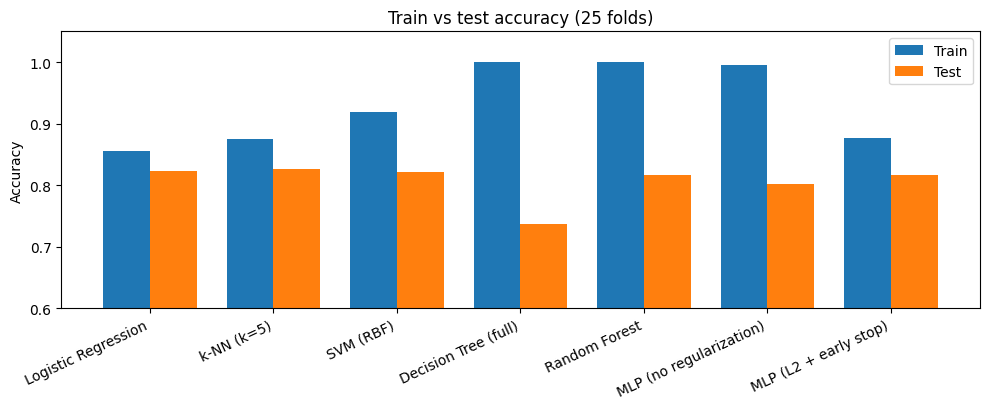

In [8]:
x = np.arange(len(table)); w = 0.38
plt.figure(figsize=(10, 4.2))
plt.bar(x - w / 2, table['Train acc'], w, label='Train'); plt.bar(x + w / 2, table['Test acc'], w, label='Test')
plt.xticks(x, table['Model'], rotation=25, ha='right'); plt.ylim(0.6, 1.05); plt.ylabel('Accuracy')
plt.title('Train vs test accuracy (25 folds)'); plt.legend(); plt.tight_layout(); plt.show()

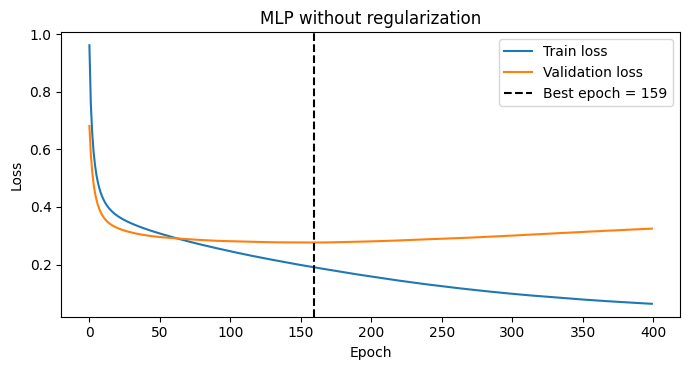

In [9]:
folds = np.array_split(np.random.default_rng(0).permutation(len(X)), 5)
tr = np.concatenate(folds[1:]); Xa, Xb = standardize(X[tr], X[folds[0]])
_, hist = train_mlp(Xa, y[tr], val=(Xb, y[folds[0]]), epochs=400)                  
hist = np.array(hist); best_ep = int(hist[:, 1].argmin())
plt.figure(figsize=(7, 3.8)); plt.plot(hist[:, 0], label='Train loss'); plt.plot(hist[:, 1], label='Validation loss')
plt.axvline(best_ep, color='k', ls='--', label=f'Best epoch = {best_ep}')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.title('MLP without regularization'); plt.legend(); plt.tight_layout(); plt.show()

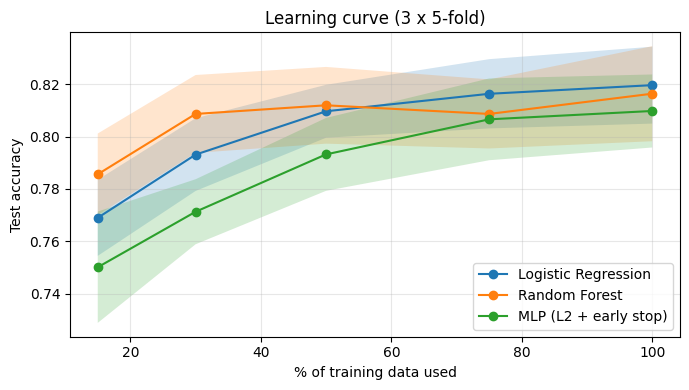

{'Logistic Regression': [0.769, 0.793, 0.81, 0.816, 0.82], 'Random Forest': [0.786, 0.809, 0.812, 0.809, 0.816], 'MLP (L2 + early stop)': [0.75, 0.771, 0.793, 0.807, 0.81]}


In [10]:
fracs = [0.15, 0.3, 0.5, 0.75, 1.0]
subset = {'Logistic Regression': models['Logistic Regression'], 'Random Forest': models['Random Forest'],
          'MLP (L2 + early stop)': models['MLP (L2 + early stop)']}
curve = {n: [[] for _ in fracs] for n in subset}
for rep in range(3):
    folds = np.array_split(np.random.default_rng(rep).permutation(len(X)), 5)
    for k in range(5):
        te = folds[k]; tr = np.concatenate([folds[i] for i in range(5) if i != k])
        for fi, fr in enumerate(fracs):
            sub = tr[np.random.default_rng(rep * 5 + k).permutation(len(tr))[:int(fr * len(tr))]]
            Xa, Xb = standardize(X[sub], X[te])
            for n, fit in subset.items():
                curve[n][fi].append(metrics(y[te], fit(Xa, y[sub], rep * 5 + k)(Xb))['acc'])

plt.figure(figsize=(7, 4))
for n, v in curve.items():
    m = np.array([np.mean(a) for a in v]); s = np.array([np.std(a) / np.sqrt(len(a)) for a in v])
    plt.plot(np.array(fracs) * 100, m, marker='o', label=n); plt.fill_between(np.array(fracs) * 100, m - s, m + s, alpha=0.2)
plt.xlabel('% of training data used'); plt.ylabel('Test accuracy'); plt.title('Learning curve (3 x 5-fold)')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()
print({n: [round(float(np.mean(a)), 3) for a in v] for n, v in curve.items()})